In [1]:
import cv2
import os
import numpy as np
import pandas as pd
from math import exp, sqrt
import matplotlib.pyplot as plt
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels
import matplotlib.image as mpimg
from sklearn.utils import shuffle
import keras
import tensorflow as tf

import tensorflow.keras.backend as K
from keras import Input
from keras.models import Model
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import  BatchNormalization, Concatenate, Add, DepthwiseConv2D, GlobalAveragePooling2D, SeparableConv2D
from tensorflow.keras.optimizers import SGD,RMSprop,Adam,Adagrad
from keras.layers import Conv2D, MaxPooling2D

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vibhingupta028/liver-histopathology-fibrosis-ultrasound-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'liver-histopathology-fibrosis-ultrasound-images' dataset.
Path to dataset files: /kaggle/input/liver-histopathology-fibrosis-ultrasound-images


# **Splitting the Data into Training and Testing**

In [3]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from keras.utils import to_categorical

# Define path to the main directory
# data_path = 'rice'
# Define class names
class_names = ['F0', 'F1', 'F2', 'F3', 'F4']
class_to_label = {name: idx for idx, name in enumerate(class_names)}

img_data_list = []
labels = []

# Load images and labels
# Corrected path to account for the nested 'Dataset' directory
dataset_path = os.path.join(path, 'Dataset', 'Dataset')
for dataset in class_names:
    img_list = os.listdir(os.path.join(dataset_path, dataset))
    print(f'Loaded images from dataset-{dataset}, total: {len(img_list)}')

    for img in img_list:
        img_path = os.path.join(dataset_path, dataset, img)
        input_img = cv2.imread(img_path)
        if input_img is None:
            continue
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)
        labels.append(class_to_label[dataset])  # Use mapped label

Loaded images from dataset-F0, total: 2114
Loaded images from dataset-F1, total: 861
Loaded images from dataset-F2, total: 793
Loaded images from dataset-F3, total: 857
Loaded images from dataset-F4, total: 1698


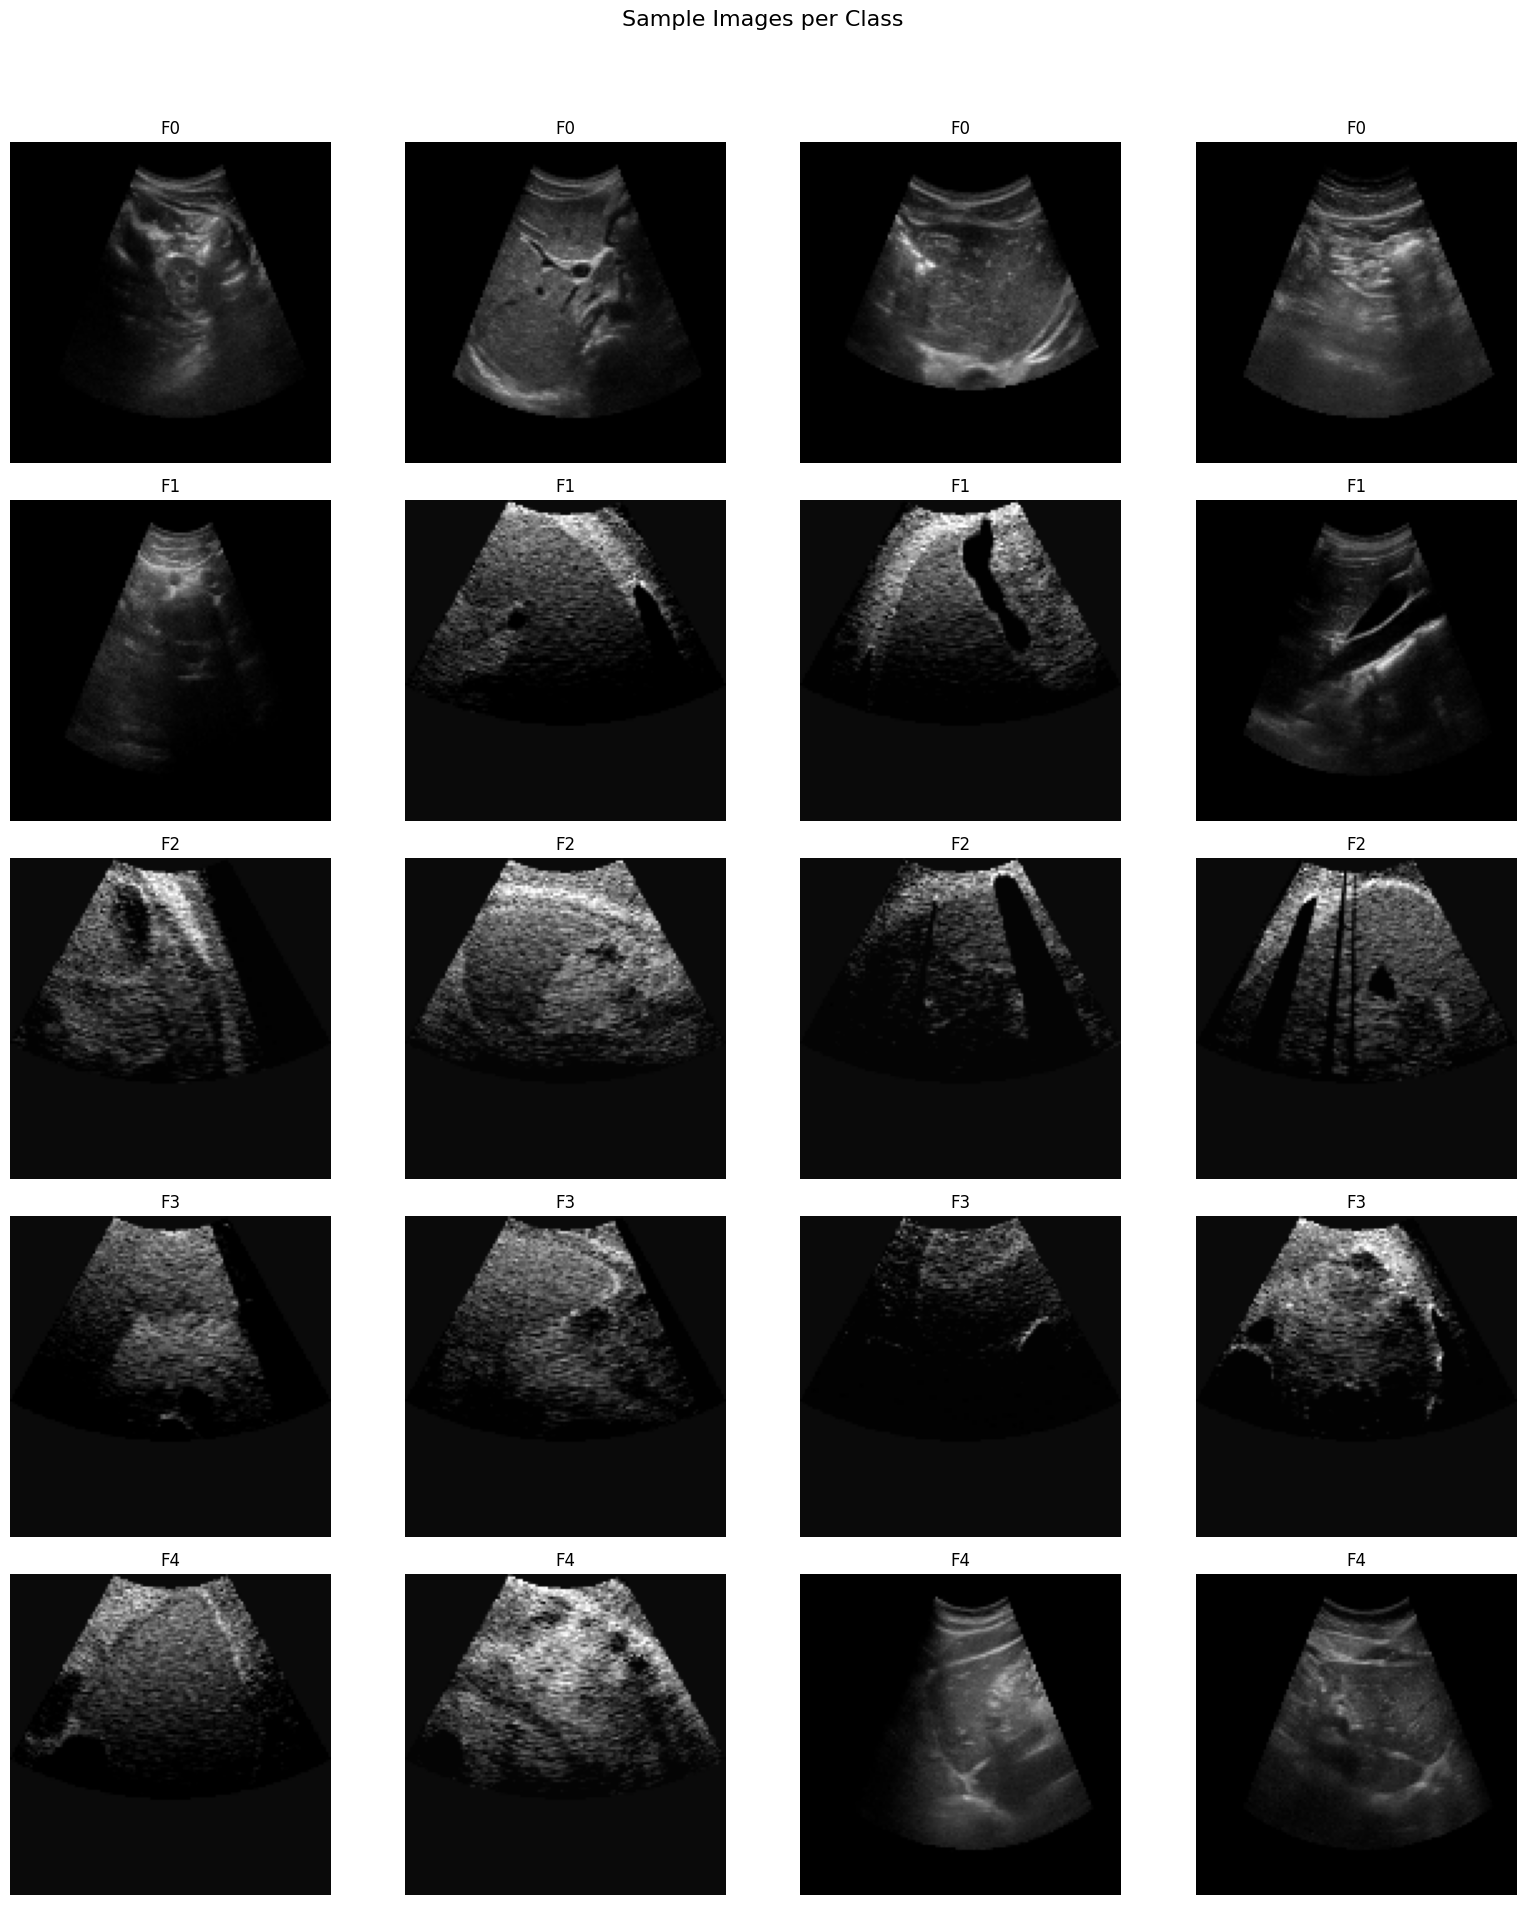

In [4]:
import matplotlib.pyplot as plt
import random

num_images_per_class = 4
plt.figure(figsize=(16, 4 * len(class_names)))

for idx, class_name in enumerate(class_names):
    class_indices = [i for i, label in enumerate(labels) if label == idx]
    sampled_indices = random.sample(class_indices, min(num_images_per_class, len(class_indices)))

    for j, rand_idx in enumerate(sampled_indices):
        plt_idx = idx * num_images_per_class + j + 1
        plt.subplot(len(class_names), num_images_per_class, plt_idx)
        plt.imshow(img_data_list[rand_idx])
        plt.title(class_name)
        plt.axis('off')

plt.suptitle("Sample Images per Class", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [5]:
# Convert to NumPy arrays and normalize
data = np.array(img_data_list, dtype="float32") / 255.0
labels = np.array(labels)

# One-hot encode labels
num_classes = len(class_names)
labels_one_hot = to_categorical(labels, num_classes)

# Train / temp split (70 / 30)
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels_one_hot,
    test_size=0.3,
    stratify=labels,
    random_state=42
)

# Stratify validation / test split (15 / 15)
y_temp_labels = np.argmax(y_temp, axis=1)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp_labels,
    random_state=42
)

# Shuffle
x_train, y_train = shuffle(x_train, y_train, random_state=42)
x_val, y_val = shuffle(x_val, y_val, random_state=42)
x_test, y_test = shuffle(x_test, y_test, random_state=42)


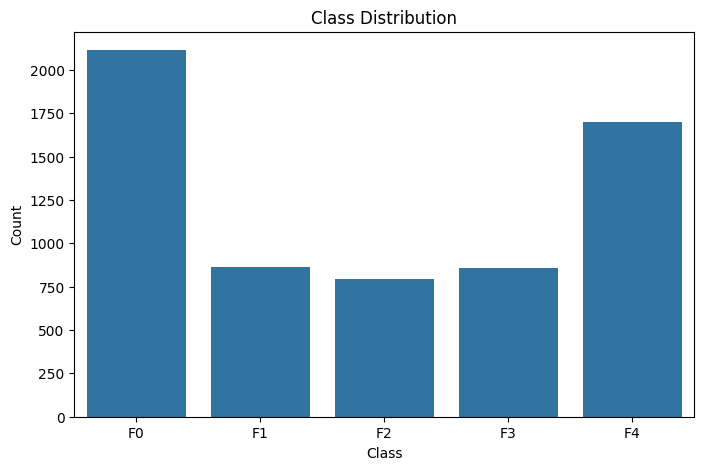

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=np.argmax(labels_one_hot, axis=1))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(ticks=range(num_classes), labels=class_names)
plt.show()

In [7]:
# Reshape
x_train = x_train.reshape(-1, 128, 128, 3)
x_val = x_val.reshape(-1, 128, 128, 3)
x_test = x_test.reshape(-1, 128, 128, 3)

# Confirm shapes
print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Train shape: (4426, 128, 128, 3)
Validation shape: (948, 128, 128, 3)
Test shape: (949, 128, 128, 3)


In [8]:
import tensorflow
METRICS = [tensorflow.keras.metrics.CategoricalAccuracy(name='accuracy'),
           tensorflow.keras.metrics.Precision(name='precision'),
           tensorflow.keras.metrics.Recall(name='recall'),
           tensorflow.keras.metrics.AUC(name='auc')]

In [9]:
from tensorflow.keras.layers import Dense, Reshape, Softmax, Permute, Add, Lambda
import tensorflow.keras.backend as K

def self_attention(input_feature_map):
    shape = K.int_shape(input_feature_map)  # (batch_size, height, width, channels)
    batch_size, height, width, channels = shape

    # Flatten the spatial dimensions (height, width) to treat them as sequence elements
    flat_feature_map = Reshape((height * width, channels))(input_feature_map)  # (batch_size, height*width, channels)

    # Compute Query, Key, and Value matrices with more complexity
    query_dense1 = Dense(channels // 4, activation='relu')(flat_feature_map)   # (batch_size, height*width, channels // 4)
    key_dense1 = Dense(channels // 4, activation='relu')(flat_feature_map)     # (batch_size, height*width, channels // 4)
    value_dense1 = Dense(channels // 2, activation='relu')(flat_feature_map)   # (batch_size, height*width, channels // 2)

    query = Dense(channels // 8)(query_dense1)  # (batch_size, height*width, channels // 8)
    key = Dense(channels // 8)(key_dense1)      # (batch_size, height*width, channels // 8)
    value = Dense(channels)(value_dense1)       # (batch_size, height*width, channels)

    # Transpose the Key for dot product
    key_transposed = Permute((2, 1))(key)  # (batch_size, channels // 8, height*width)

    # Compute attention scores (dot product between Query and transposed Key)
    attention_scores = Lambda(lambda x: K.batch_dot(x[0], x[1]),
                              output_shape=(height * width, height * width))([query, key_transposed])

    # Apply softmax to the attention scores
    attention_scores = Softmax()(attention_scores)  # (batch_size, height*width, height*width)

    # Apply the attention scores to the Value matrix
    attention_output = Lambda(lambda x: K.batch_dot(x[0], x[1]),
                              output_shape=(height * width, channels))([attention_scores, value])  # (batch_size, height*width, channels)

    # Reshape the attention output back to the original feature map shape
    attention_output = Reshape((height, width, channels))(attention_output)

    # Add the input to the attention output (residual connection)
    output = Add()([input_feature_map, attention_output])

    return output

In [10]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, ReLU, DepthwiseConv2D, Multiply,
    Concatenate, GlobalAveragePooling2D, Dense, Activation, Add, Dropout
)
from tensorflow.keras.models import Model

# Input Layer
input_layer = tf.keras.Input(shape=(128, 128, 3))

# Initial Convolution Block
x = Conv2D(32, (3, 3), strides=(2, 2), padding='same', activation='relu')(input_layer)
x = BatchNormalization()(x)
x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Depthwise Separable Convolution Block
x = DepthwiseConv2D((3, 3), padding='same', strides=(1, 1))(x)
x = BatchNormalization()(x)
x = ReLU()(x)

# Dilated Convolution Branches for Multi-scale Features
x1 = Conv2D(128, (3, 3), dilation_rate=1, padding='same', activation='relu')(x)
x1 = BatchNormalization()(x1)
x2 = Conv2D(128, (3, 3), dilation_rate=2, padding='same', activation='relu')(x)
x2 = BatchNormalization()(x2)
x3 = Conv2D(128, (3, 3), dilation_rate=5, padding='same', activation='relu')(x)
x3 = BatchNormalization()(x3)

# Adding Branch Outputs
A1 = Add()([x1, x2, x3])

# Intermediate Convolutional Block
x4 = Conv2D(128, (3, 3), padding='same', activation='relu')(A1)
x4 = BatchNormalization()(x4)

x = self_attention(x4)

# Concatenation Block
C1 = Concatenate()([x, x2, x3])
x5 = Conv2D(128, (3, 3), padding='same', activation='relu')(C1)

# Residual Connection
C2 = Concatenate()([x5, x])
x = Conv2D(256, (3, 3), padding='same', activation='relu')(C2)
x = BatchNormalization()(x)

# Expanded Depthwise Separable Convolution Block
x = DepthwiseConv2D((3, 3), padding='same', strides=(1, 1))(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = Conv2D(256, (1, 1), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Additional Residual Connection
residual = Conv2D(256, (1, 1), padding='same', activation='relu')(C2)
x = Add()([x, residual])

# Further Convolutional Layers
x = Conv2D(256, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(512, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Global Pooling
x = GlobalAveragePooling2D()(x)

# Fully Connected Layers
x = Dense(512, activation='relu')(x)
x = Dense(256, activation='relu')(x)
output = Dense(5, activation='softmax')(x)

# Model Compilation
model = Model(inputs=input_layer, outputs=output)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics= METRICS)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d    │ (None, 64, 64,    │        640 │ batch_normalizat… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ add[0][0]         │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,756,133 (14.33 MB)

 Trainable params: 3,751,717 (14.31 MB)

 Non-trainable params: 4,416 (17.25 KB)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

In [12]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [13]:
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint = ModelCheckpoint('model-{epoch:03d}-{accuracy:03f}-{val_accuracy:03f}.keras',
    verbose=1,
    monitor='val_accuracy',
    save_best_only=True,
    mode='auto')

In [14]:
import time
start_train = time.time()
history = model.fit(x_train, y_train, batch_size = 16, epochs = 50,
                    validation_data = (x_val , y_val), callbacks=[checkpoint], verbose =1)
end_train = time.time()
training_time = end_train - start_train
print(f"\nTraining time: {training_time:.2f} seconds")

Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.5059 - auc: 0.8285 - loss: 1.1196 - precision: 0.6594 - recall: 0.3348
Epoch 1: val_accuracy improved from None to 0.14135, saving model to model-001-0.555581-0.141350.keras

Epoch 1: finished saving model to model-001-0.555581-0.141350.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 228s 635ms/step - accuracy: 0.5556 - auc: 0.8630 - loss: 0.9972 - precision: 0.7465 - recall: 0.3938 - val_accuracy: 0.1414 - val_auc: 0.3861 - val_loss: 6.0339 - val_precision: 0.1328 - val_recall: 0.0759
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.6402 - auc: 0.9070 - loss: 0.8248 - precision: 0.8138 - recall: 0.4965
Epoch 2: val_accuracy improved from 0.14135 to 0.25316, saving model to model-002-0.652960-0.253165.keras

Epoch 2: finished saving model to model-002-0.652960-0.253165.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 123s 445ms/step - accuracy: 0.6530 - auc: 0.9168 - loss: 0.7837 - precision: 0.8274 - recall: 0.5176 - val_accu

In [16]:
model.load_weights('/content/model-032-0.985088-0.976793.keras')
print("Model is loaded")

Model is loaded


In [17]:
loss, acc, prec, rec, auc = model.evaluate(x_test, y_test)

30/30 ━━━━━━━━━━━━━━━━━━━━ 53s 948ms/step - accuracy: 0.9715 - auc: 0.9924 - loss: 0.1321 - precision: 0.9725 - recall: 0.9694


In [18]:
# -----------------------------------------------------------------
# INFERENCE TIME (measure prediction speed)
# -----------------------------------------------------------------
start_inf = time.time()
preds = model.predict(x_test)
end_inf = time.time()

inference_time = end_inf - start_inf
print(f"\nInference time on test set: {inference_time:.2f} seconds")

30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 340ms/step

Inference time on test set: 13.27 seconds


In [19]:
# -----------------------------------------------------------------
# SAVE MODEL AND CHECK SIZE
# -----------------------------------------------------------------
import os
import tensorflow as tf
from datetime import datetime

os.makedirs("saved_models", exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Version 1: deployment-safe HDF5
h5_path = f"saved_models/livermodel_{timestamp}.h5"
model.save(h5_path)
print(f"Saved H5 model: {h5_path}")

# Version 2: TensorFlow SavedModel (optional, backup)
tf_path = f"saved_models/livermodel_tf_{timestamp}"
# Use model.export for TensorFlow SavedModel format
model.export(tf_path)
print(f"Saved TF model: {tf_path}")

# Version 3: Keras v3 format (only if you want it)
keras_path = f"saved_models/livermodel_{timestamp}.keras"
model.save(keras_path)
print(f"Saved Keras model: {keras_path}")

Saved H5 model: saved_models/livermodel_20260712_165552.h5
Saved artifact at 'saved_models/livermodel_tf_20260712_165552'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135264442126544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442128848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442130384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442131344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442131152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442130576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442130960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442131536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135264442126928: TensorSpec(shape=(), dtype=tf.resource, name=None)
 

In [ ]:

# model.save("livermodel.keras")

# print("\nSaved model as livermodel.keras")

# model_size_mb = os.path.getsize("livermodel.keras") / (1024 * 1024)
# print(f"Model size: {model_size_mb:.2f} MB")

In [20]:
import shutil

shutil.make_archive(
    "liver_models_bundle",
    "zip",
    "saved_models"
)

print("Zipped all models into liver_models_bundle.zip")


Zipped all models into liver_models_bundle.zip


In [21]:
from google.colab import files
files.download("liver_models_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 276ms/step


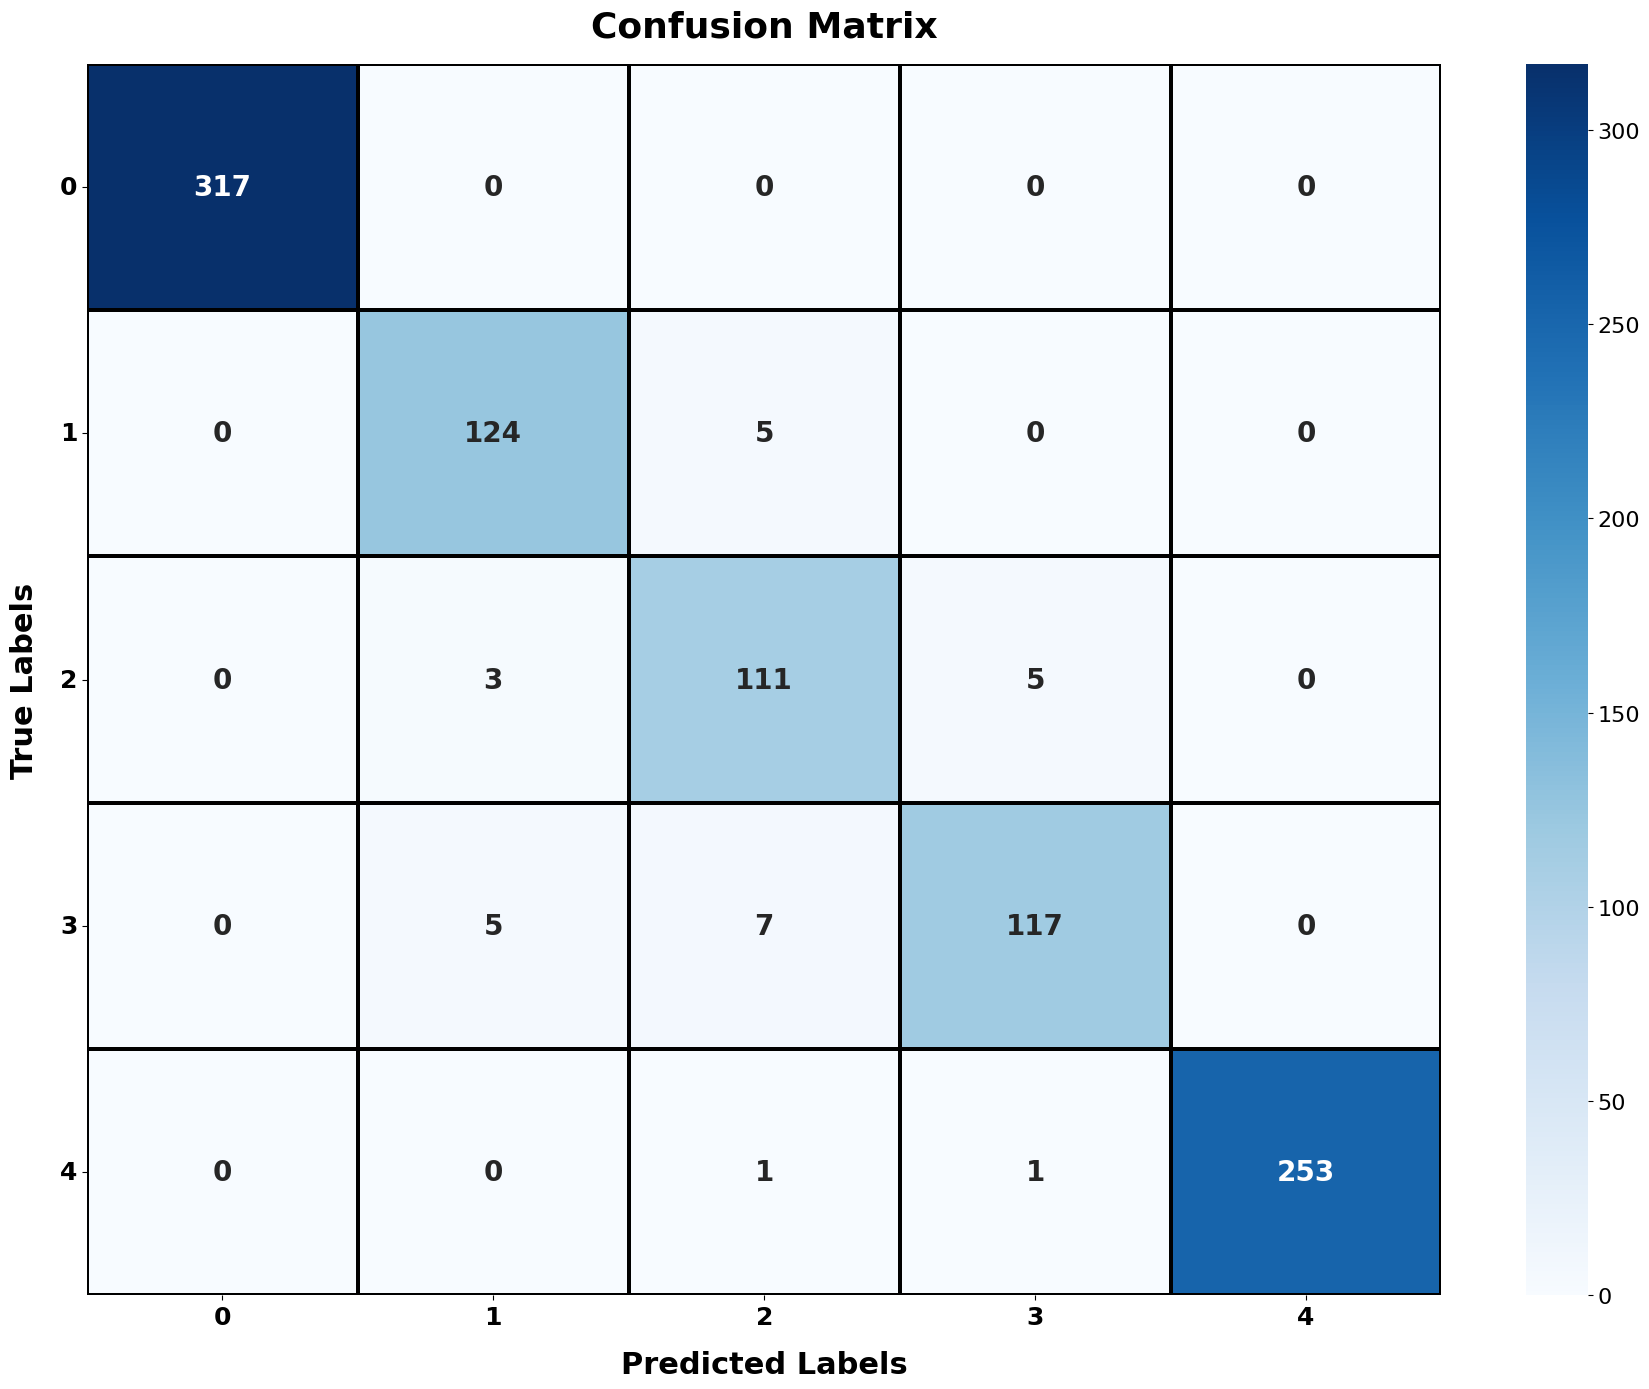

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels

# Predictions
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# True labels
y_true = np.argmax(y_test, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plot
plt.figure(figsize=(18, 14))

ax = sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    annot_kws={"size": 20, "weight": "bold"},
    linewidths=1.5,
    linecolor="black"
)

# Axis labels and title
ax.set_title("Confusion Matrix", fontsize=26, fontweight="bold", pad=20)
ax.set_xlabel("Predicted Labels", fontsize=22, fontweight="bold", labelpad=15)
ax.set_ylabel("True Labels", fontsize=22, fontweight="bold", labelpad=15)

# Tick labels
labels = unique_labels(y_true)
ax.set_xticklabels(labels, fontsize=18, fontweight="bold")
ax.set_yticklabels(labels, fontsize=18, fontweight="bold", rotation=0)

# Color bar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.show()

30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 299ms/step


/tmp/ipykernel_420/892001223.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_classes)


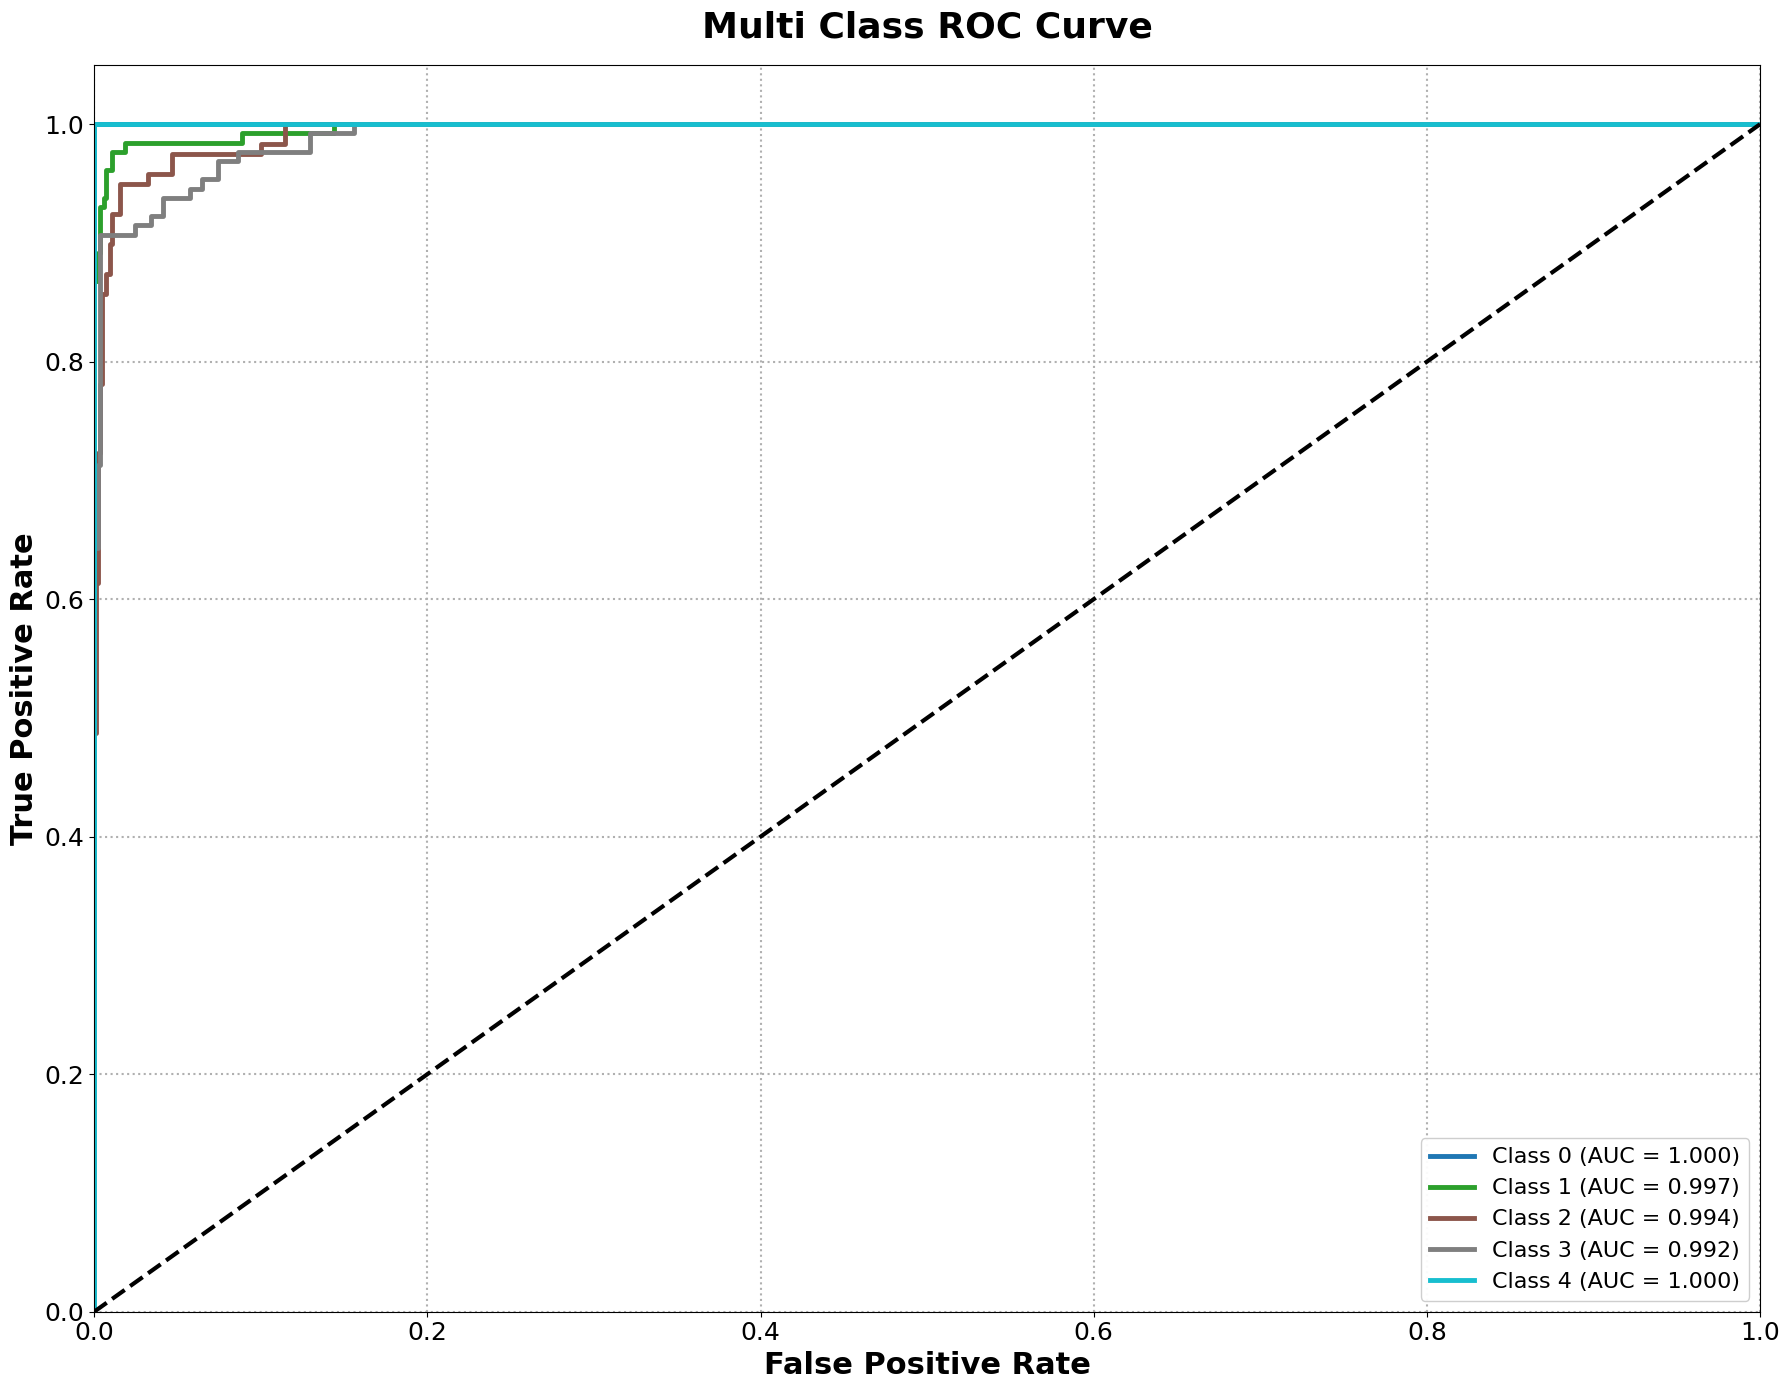

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

num_classes = 5  # update if needed

# Evaluate the model
loss, acc, prec, rec, auc_score = model.evaluate(x_test, y_test, verbose=0)

# Predictions
y_pred = model.predict(x_test)

# Binarize labels
y_true_bin = label_binarize(y_test, classes=np.arange(num_classes))

# ROC computation
fpr, tpr, roc_auc = {}, {}, {}
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(18, 14))

colors = plt.cm.get_cmap("tab10", num_classes)

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=3.5,
        color=colors(i),
        label=f"Class {i} (AUC = {roc_auc[i]:.3f})"
    )

# Reference line
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=3, color="black")

# Axis limits
plt.xlim(0, 1)
plt.ylim(0, 1.05)

# Labels and title (large and clear)
plt.xlabel("False Positive Rate", fontsize=22, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=22, fontweight="bold")
plt.title("Multi Class ROC Curve", fontsize=26, fontweight="bold", pad=20)

# Ticks
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Legend
plt.legend(
    loc="lower right",
    fontsize=16,
    frameon=True,
    framealpha=0.95
)

# Grid for readability
plt.grid(True, linestyle=":", linewidth=1.5)

plt.tight_layout()
plt.show()

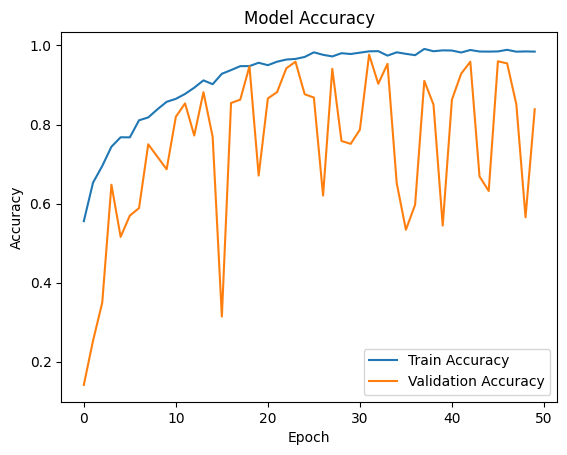

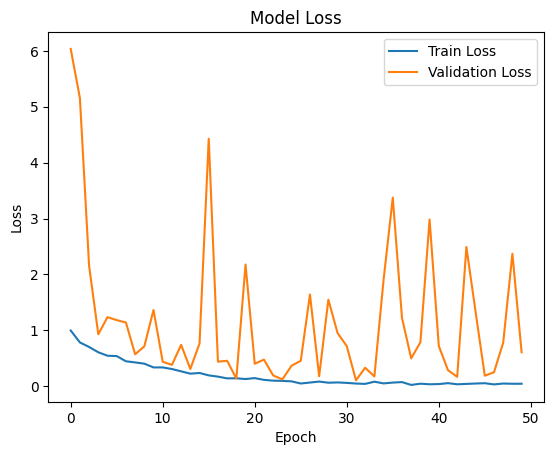

In [24]:
import matplotlib.pyplot as plt

def plot_accuracy(history):
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

def plot_loss(history):
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()
plot_accuracy(history)
plot_loss(history)

30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 257ms/step
Class-wise metrics:
Class 0:
  Precision   : 1.0000
  Recall      : 1.0000
  Specificity : 1.0000
  PLR         : inf
  NLR         : 0.0000
  F1-Score    : 1.0000

Class 1:
  Precision   : 0.9394
  Recall      : 0.9612
  Specificity : 0.9902
  PLR         : 98.5271
  NLR         : 0.0391
  F1-Score    : 0.9502

Class 2:
  Precision   : 0.8952
  Recall      : 0.9328
  Specificity : 0.9843
  PLR         : 59.5540
  NLR         : 0.0683
  F1-Score    : 0.9136

Class 3:
  Precision   : 0.9512
  Recall      : 0.9070
  Specificity : 0.9927
  PLR         : 123.9535
  NLR         : 0.0937
  F1-Score    : 0.9286

Class 4:
  Precision   : 1.0000
  Recall      : 0.9922
  Specificity : 1.0000
  PLR         : inf
  NLR         : 0.0078
  F1-Score    : 0.9961

Overall AUC: 0.9967


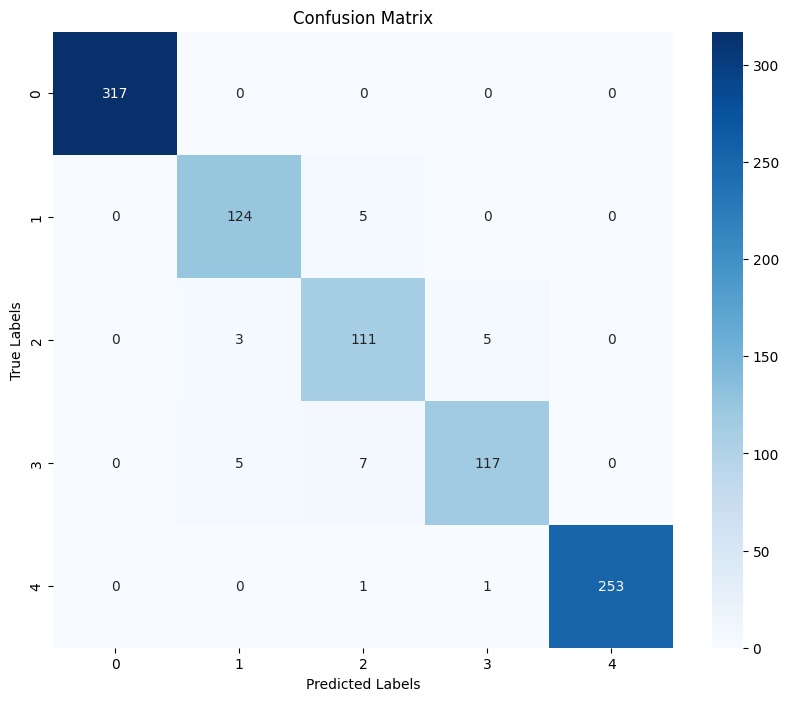

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Assuming model, x_test, y_test are defined

# Get predicted probabilities and predicted class labels
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# Convert one-hot encoded y_test back to class labels
y_true = np.argmax(y_test, axis=1)

# Define class labels explicitly to ensure consistent ordering
labels = np.arange(y_pred.shape[1])  # e.g., array([0, 1, 2, ..., n_classes-1])

# Create confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes, labels=labels)

# Compute class-wise metrics from sklearn report
report = classification_report(y_true, y_pred_classes, output_dict=True, labels=labels)

# Compute specificity, PLR, and NLR for each class
specificity = {}
plr = {}
nlr = {}

for i in labels:
    tp = conf_matrix[i, i]
    fn = np.sum(conf_matrix[i, :]) - tp
    fp = np.sum(conf_matrix[:, i]) - tp
    tn = np.sum(conf_matrix) - (tp + fp + fn)

    sens = tp / (tp + fn) if (tp + fn) > 0 else 0  # Sensitivity (Recall)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0  # Specificity

    specificity[i] = spec
    # Positive Likelihood Ratio (PLR) = Sensitivity / (1 - Specificity)
    plr[i] = sens / (1 - spec) if (1 - spec) > 0 else np.inf
    # Negative Likelihood Ratio (NLR) = (1 - Sensitivity) / Specificity
    nlr[i] = (1 - sens) / spec if spec > 0 else np.inf

# Print class-wise results including PLR and NLR
print("Class-wise metrics:")
for label in labels:
    print(f"Class {label}:")
    print(f"  Precision   : {report[str(label)]['precision']:.4f}")
    print(f"  Recall      : {report[str(label)]['recall']:.4f}")
    print(f"  Specificity : {specificity[label]:.4f}")
    print(f"  PLR         : {plr[label]:.4f}")
    print(f"  NLR         : {nlr[label]:.4f}")
    print(f"  F1-Score    : {report[str(label)]['f1-score']:.4f}")
    print()

# Compute AUC if applicable (multi-class)
if y_pred.shape[1] > 1:
    auc = roc_auc_score(y_test, y_pred, multi_class="ovr")
    print(f"Overall AUC: {auc:.4f}")

# Plot confusion matrix using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels,
            yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [26]:
from sklearn.metrics import roc_auc_score

# Assuming y_test is one-hot encoded and y_pred are predicted probabilities

n_classes = y_test.shape[1]

for i in range(n_classes):
    # True binary labels for class i vs rest
    y_true_binary = y_test[:, i]
    # Predicted probabilities for class i
    y_pred_prob = y_pred[:, i]

    auc_per_class = roc_auc_score(y_true_binary, y_pred_prob)
    print(f"AUC for class {i}: {auc_per_class:.4f}")


AUC for class 0: 1.0000
AUC for class 1: 0.9975
AUC for class 2: 0.9941
AUC for class 3: 0.9920
AUC for class 4: 1.0000


GradCam

In [27]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()


In [29]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from zipfile import ZipFile

# --- CONFIGURATION ---
output_dir = "gradcam_outputs"
zip_filename = "gradcams.zip"
img_size = (128, 128)
last_conv_layer_name = "conv2d_11"  # ← change if needed
max_images = len(x_test)  # set a smaller number for testing, e.g., 10
# ----------------------

# Create output directory
os.makedirs(output_dir, exist_ok=True)

def get_img_array_from_tensor(img_tensor, size):
    # Reshape and resize if necessary
    img = tf.image.resize(img_tensor, size)
    img = tf.expand_dims(img, axis=0)
    return img

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy(), int(pred_index)

def save_gradcam_overlay(image, heatmap, output_path, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = Image.fromarray((jet_heatmap * 255).astype(np.uint8))
    jet_heatmap = jet_heatmap.resize((image.shape[1], image.shape[0]))
    jet_heatmap = np.array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + image
    superimposed_img = np.uint8(superimposed_img)

    Image.fromarray(superimposed_img).save(output_path)

# --- Generate and save all Grad-CAMs ---
for idx in range(min(max_images, len(x_test))):
    img = x_test[idx]
    label = np.argmax(y_test[idx]) if y_test.ndim == 2 else y_test[idx]

    # Prepare image for model
    img_array = get_img_array_from_tensor(img, img_size)

    # Generate heatmap
    heatmap, pred_class = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    # Convert image back to uint8
    img_uint8 = np.uint8(img * 255)

    # Output filename
    filename = f"img_{idx}_true_{label}_pred_{pred_class}.png"
    output_path = os.path.join(output_dir, filename)

    # Save overlay image
    save_gradcam_overlay(img_uint8, heatmap, output_path)

print(f"Saved {min(max_images, len(x_test))} Grad-CAM images to '{output_dir}'")

# --- Zip the directory ---
with ZipFile(zip_filename, 'w') as zipf:
    for file in os.listdir(output_dir):
        zipf.write(os.path.join(output_dir, file), arcname=file)

print(f"Grad-CAM images zipped into '{zip_filename}'")

# Optional: Clean up image files after zipping
# import shutil
# shutil.rmtree(output_dir)


/tmp/ipykernel_420/1537174109.py:47: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = plt.cm.get_cmap("jet")


Saved 949 Grad-CAM images to 'gradcam_outputs'
Grad-CAM images zipped into 'gradcams.zip'


/tmp/ipykernel_420/3878389357.py:44: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = plt.cm.get_cmap("jet")


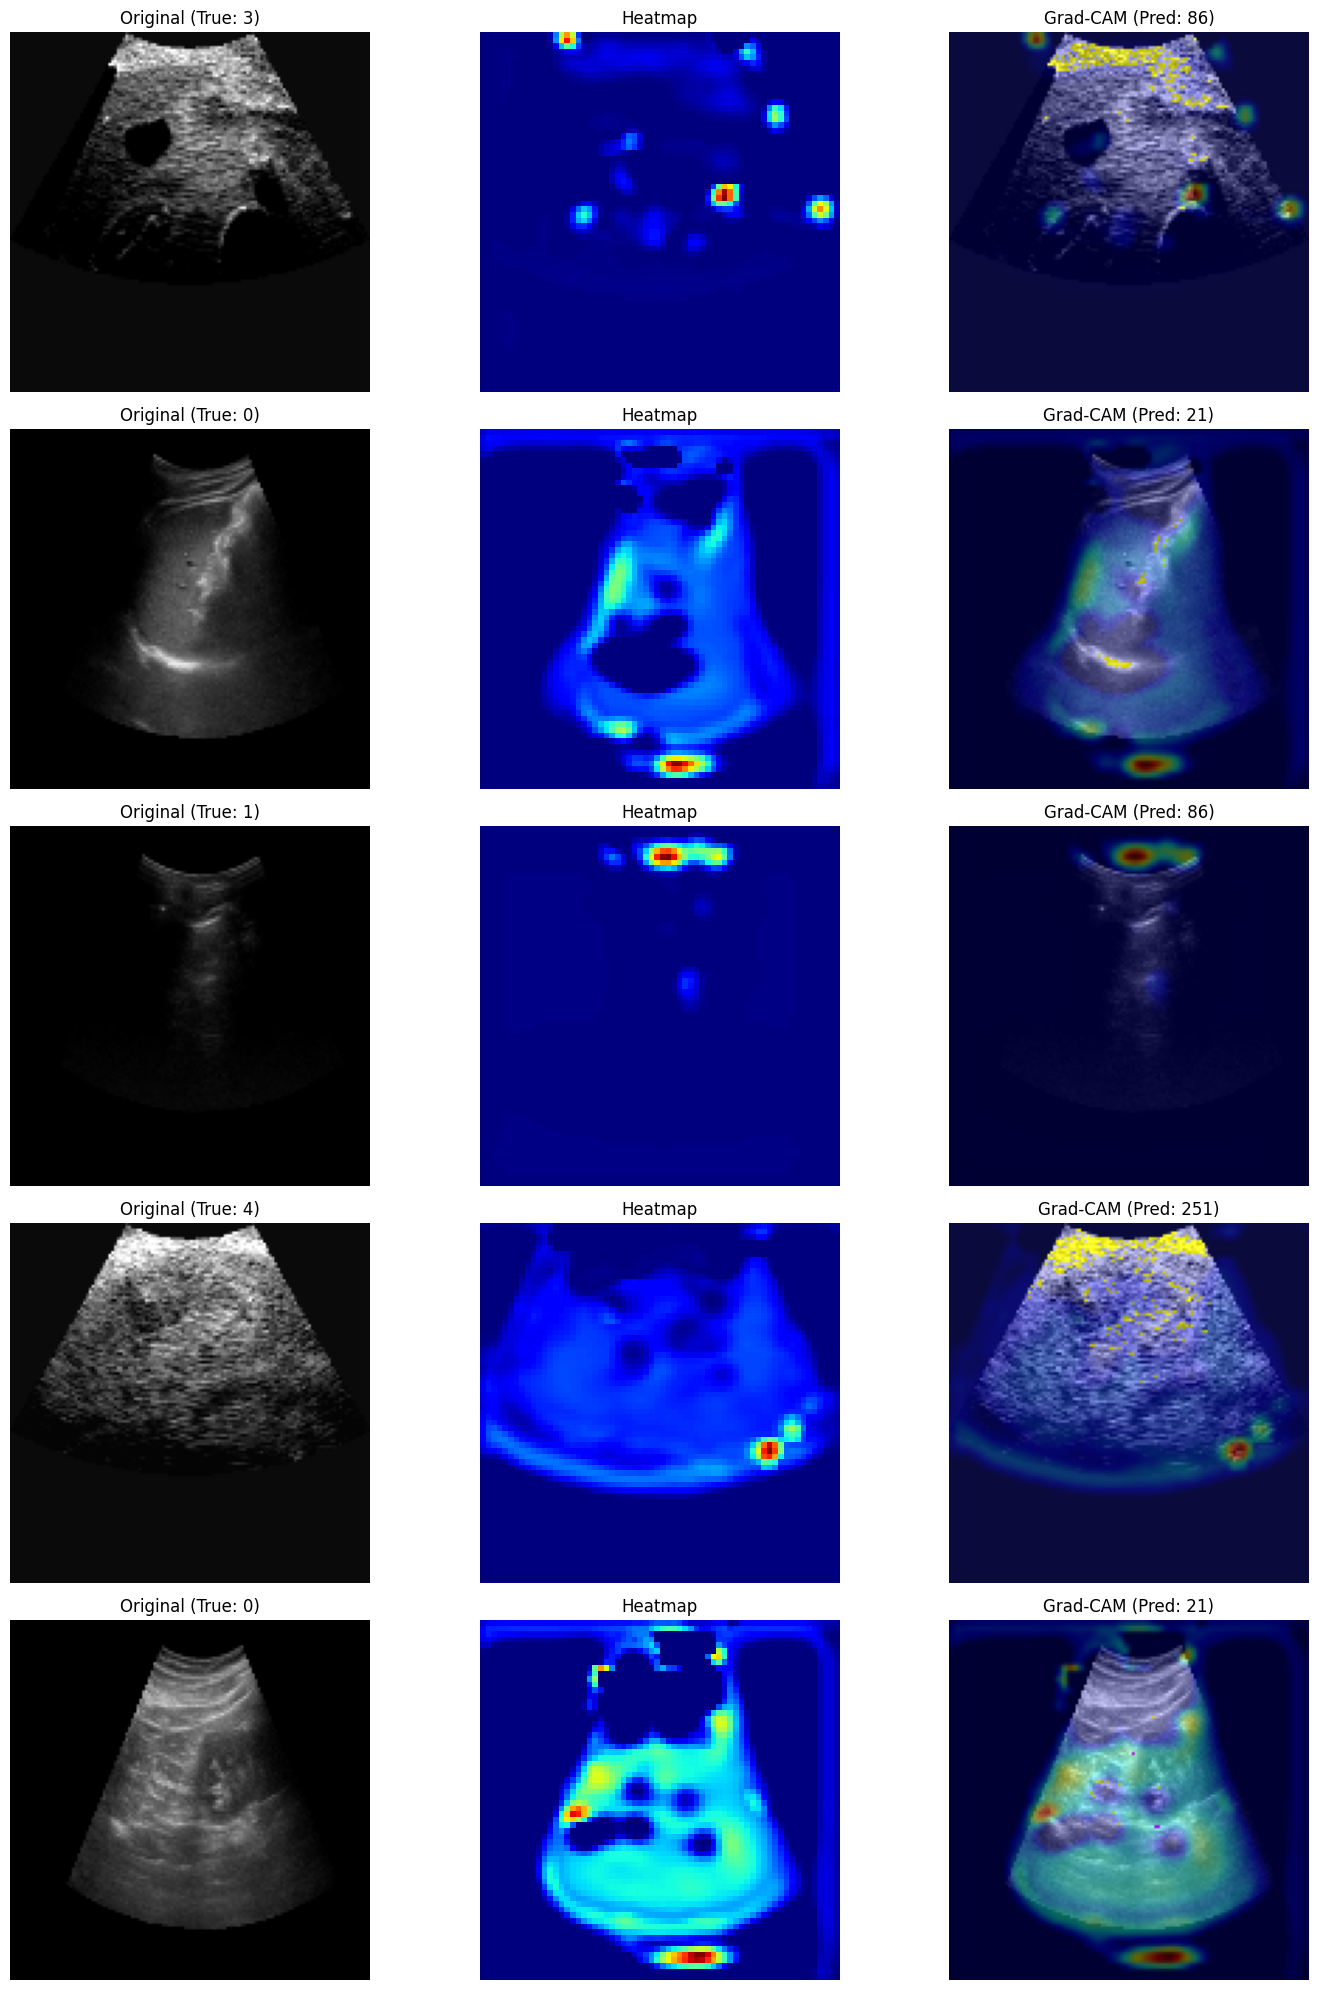

In [30]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from zipfile import ZipFile

# --- CONFIGURATION ---
output_dir = "gradcam_outputs"
zip_filename = "gradcams1.zip"
img_size = (128, 128)
last_conv_layer_name = "conv2d_11"
max_images_to_display = 5
# ----------------------

def get_img_array_from_tensor(img_tensor, size):
    # Reshape and resize if necessary
    img = tf.image.resize(img_tensor, size)
    img = tf.expand_dims(img, axis=0)
    return img

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy(), int(pred_index)

def save_and_display_gradcam_overlay(image, heatmap, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    jet = plt.cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = Image.fromarray((jet_heatmap * 255).astype(np.uint8))
    jet_heatmap = jet_heatmap.resize((image.shape[1], image.shape[0]))
    jet_heatmap = np.array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + image
    superimposed_img = np.uint8(superimposed_img)
    return superimposed_img


# --- Visualize sample Grad-CAMs ---
plt.figure(figsize=(15, max_images_to_display * 4))

# Remove the last layer from the model for Grad-CAM
model_no_softmax = tf.keras.models.Model(
    model.inputs, model.layers[-2].output
)

for idx in range(min(max_images_to_display, len(x_test))):
    img = x_test[idx]
    true_label = np.argmax(y_test[idx]) if y_test.ndim == 2 else y_test[idx]

    # Prepare image for model
    img_array = get_img_array_from_tensor(img, img_size)

    # Generate heatmap
    heatmap, pred_class = make_gradcam_heatmap(img_array, model_no_softmax, last_conv_layer_name)

    # Convert image back to uint8
    img_uint8 = np.uint8(img * 255)

    # Create superimposed image
    superimposed_img = save_and_display_gradcam_overlay(img_uint8, heatmap)

    # Display original image
    plt.subplot(max_images_to_display, 3, idx * 3 + 1)
    plt.imshow(img_uint8)
    plt.title(f"Original (True: {true_label})")
    plt.axis('off')

    # Display heatmap
    plt.subplot(max_images_to_display, 3, idx * 3 + 2)
    plt.imshow(heatmap, cmap='jet')
    plt.title("Heatmap")
    plt.axis('off')

    # Display superimposed image
    plt.subplot(max_images_to_display, 3, idx * 3 + 3)
    plt.imshow(superimposed_img)
    plt.title(f"Grad-CAM (Pred: {pred_class})")
    plt.axis('off')

plt.tight_layout()
plt.show()